# Estimating the causal impact of Banco Pichincha's app outage










**Context**

On August 2nd, 2025, Banco Pichincha’s mobile app became inoperable following a server update. The outage sparked widespread public outrage, which was amplified by the circulation of a viral video showing the bank’s president in a heated exchange with a customer.

In the aftermath, customers began to boycott the bank, with many withdrawing their deposits. This raises a key question:

**What was the causal impact of this event on Banco Pichincha’s bottom line?**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

**Step 1:**
Construct a data set with Banco Pichincha's deposits and its competitors and normalize the data


Source: Superintendencia de Bancos

In [22]:
#import data set
df = pd.read_excel('data_bpich.xlsx')

df.columns = df.iloc[0]   # set first row as column names
df = df[1:]               # drop the first row from the data
df = df.reset_index(drop=True)  # optional: reset index

df = df.iloc[::-1].reset_index(drop=True)



df=df.drop(columns=['Mes','Anio','CUENTA','BANCO ATLÁNTIDA S.A.','BP BANCO  DESARROLLO DE LOS PUEBLOS  S.A., CODESARROLLO'])

Normalize the data and analize trend of deposits across banks

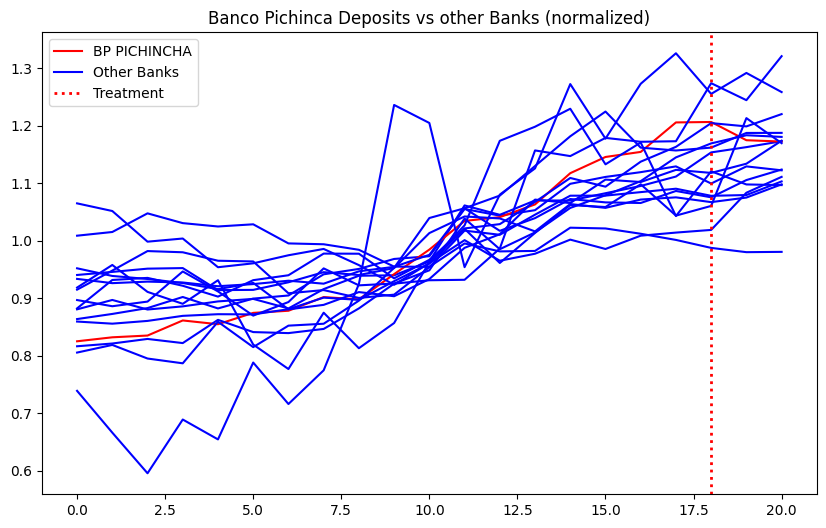

In [103]:
plt.figure(figsize=(10, 6))

for col in df.columns.tolist():
    df_scale = df[col] / df[col].mean()
    if col == 'BP PICHINCHA':
        plt.plot(df_scale, label=col, color='red')
    else:
        plt.plot(df_scale, color='blue')

plt.plot([], [], color='blue', label='Other Banks') # Add a proxy for "Other Banks" in the legend
plt.title('Banco Pichinca Deposits vs other Banks (normalized)')
plt.axvline(x=18, color='red', linestyle=':', linewidth=2, label='Treatment')
plt.legend()


plt.show()

In [26]:
df_scaled=pd.DataFrame()

for i in df.columns.tolist():
  df_scaled[i]=df[i]/df[i].mean()

df_scaled.tail()

,BP GUAYAQUIL,BP PACIFICO,BP PICHINCHA,BP PRODUBANCO,BP AUSTRO,BP BOLIVARIANO,BP DINERS,BP GENERAL RUMIÑAHUI,BP INTERNACIONAL,BP LOJA,BP MACHALA,BP SOLIDARIO,BP PROCREDIT,BP AMAZONAS,BP BANCO COMERCIAL DE MANABI,BP COOPNACIONAL
16,1.095107,1.119117,1.154328,1.065478,1.137358,1.071452,1.272822,1.098026,1.101954,1.103507,1.084391,1.008613,1.161727,1.170603,1.171951,1.011974
17,1.111484,1.129146,1.205611,1.086379,1.163148,1.075296,1.325886,1.043539,1.123085,1.144809,1.090308,1.014,1.156789,1.042788,1.172897,1.001245
18,1.153451,1.09932,1.206385,1.075326,1.204437,1.066973,1.255217,1.06037,1.117803,1.169146,1.077968,1.018641,1.161816,1.12057,1.273859,0.987365
19,1.162639,1.129144,1.174663,1.105357,1.198704,1.074932,1.291673,1.213119,1.133808,1.183317,1.07931,1.083322,1.187309,1.097743,1.244318,0.979947
20,1.17291,1.122307,1.172324,1.123659,1.220081,1.097971,1.258399,1.169526,1.173859,1.180429,1.102986,1.110912,1.187446,1.096598,1.320841,0.980481


**Step 2:** Train a synthetic control model to estimate how Pichincha Bank would have performed in the absence of the app outage. The dependent variable is Pichincha Bank’s deposit levels prior to the outage (treatment unit), and the independent variables are the deposit levels of competitor banks (donor pool).

The objective is to construct a counterfactual trajectory — a “synthetic Pichincha Bank” — that reflects what its deposits would have been had the outage not occurred. Using the pre-outage training data, we learn the optimal weighted combination of competitors that best reproduces Pichincha Bank’s behavior before the shock. These weights are then applied to predict the bank’s post-outage counterfactual.**bold text**

In [67]:
X_train=df_scaled.drop(columns=['BP PICHINCHA'])[0:19]

In [68]:
y_train=df_scaled['BP PICHINCHA'][0:19]


In [85]:
from sklearn.linear_model  import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alpha=0.0005

X_pred=df_scaled.drop(columns=['BP PICHINCHA'])

model = Lasso(alpha=alpha, max_iter=50_000)
model.fit(X_train, y_train)


y_pred = model.predict(X_pred)

# Get coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 0.001790264264878716
Coefficients: [ 0.          0.          0.          0.68201733  0.          0.06618626
  0.          0.          0.08741195  0.         -0.          0.15710466
 -0.          0.00922232  0.        ]


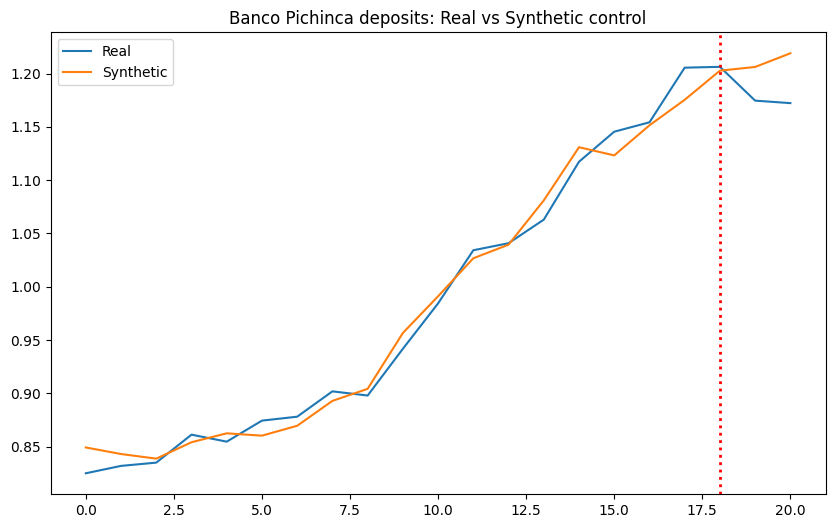

In [101]:
y_pred=pd.DataFrame(y_pred)

plt.figure(figsize=(10, 6))
plt.plot(df_scaled['BP PICHINCHA'],label='Real')
plt.plot(y_pred,label='Synthetic')
plt.axvline(x=18, color='red', linestyle=':', linewidth=2)
plt.title('Banco Pichinca deposits: Real vs Synthetic control')
plt.legend()
plt.show()

We then estimate the difference between synthetic Pichincha Bank and the real one. The difference is the causal impact of the

In [87]:
average_treatment_effect=df_scaled['BP PICHINCHA'][20]-y_pred[0][20]

print(average_treatment_effect)


-0.046789663508798096


In [92]:
#Pichincha banks ROA is between 0.4% and 0.8%. THerefore:
ROA_low=0.005
ROA_high=0.008
ROA=[ROA_high,ROA_low]

potential_loses=[average_treatment_effect*r*1000*df['BP PICHINCHA'].mean() for r in ROA]


print(f"In the pessimistic scenario, BP lost: ${-potential_loses[0]:,.0f} U.S. dollars")
print(f"In the pessimistic scenario, BP lost: ${-potential_loses[1]:,.0f} U.S. dollars")

In the pessimistic scenario, BP lost: $3,472,165 U.S. dollars
In the pessimistic scenario, BP lost: $2,170,103 U.S. dollars


In [94]:
average_treatment_effect*1000*df['BP PICHINCHA'].mean()

np.float64(-434020564.8614047)

# Step 3
Perform a placebo test to assess the statistical significance of the treatment effect observed in the synthetic control analysis.In other words, see if treatment is statistically significant

In [45]:

#step 1: define a function that assigns randomly a treatment and the rest of variables as controls

def random_treatment(data, exclude=['BP PICHINCHA']):
    candidates = [c for c in data.columns if c != exclude]
    placebo_bank = np.random.choice(candidates)
    placebo_treatment = data[placebo_bank]
    control = data.drop(columns=placebo_bank)
    return placebo_treatment, control

In [50]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

def lasso_regression(placebo_treatment, control, alpha=2000):
    # t0 = treatment index (third from the end)
    t0 = len(placebo_treatment) - 3

    # Split
    y_pre  = placebo_treatment.iloc[:t0]          # pre
    X_pre  = control.iloc[:t0]
    y_post = placebo_treatment.iloc[t0+2:]        # post (here last 2 rows)
    X_post = control.iloc[t0+2:]

    # Fit on pre only, predict post
    model = Lasso(alpha=alpha, max_iter=50_000)
    model.fit(X_pre, y_pre)
    y_post_hat = model.predict(X_post)

    # Effect: actual - synthetic
    eff = y_post.values - y_post_hat
    ate = float(np.mean(eff))                     # average post-period effect

    # # Normalize (percent) using *pre* mean — robust, interpretable
    # denom = float(y_pre.mean())
    # if denom == 0:
    #     # fallback: use synthetic at t0 or abs(pre mean) to avoid div-by-zero
    #     denom = float(np.mean(model.predict(control.iloc[[t0]]))) or 1.0

    # ate_percent = ate / denom
    return ate

In [51]:
#step 3:estimate PV based on the number of placebo tests that are above

placebo_tests=[]
for i in range(0,1000):
  placebo_treatment,control=random_treatment(df_scaled)
  placebo_tests.append(lasso_regression(placebo_treatment,control))


In [52]:
placebo_tests=pd.DataFrame(placebo_tests)
p_value = (placebo_tests[0] <= average_treatment_effect).mean()

print(p_value)

0.0


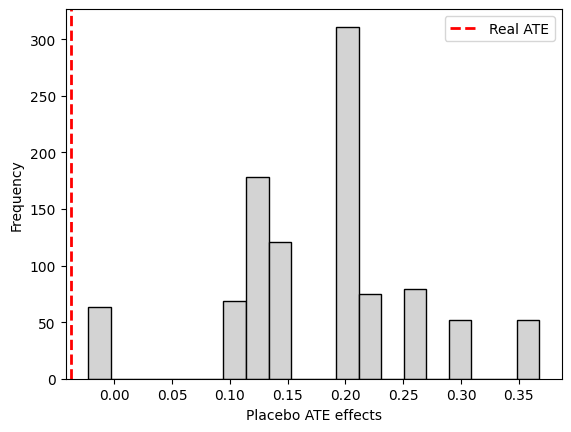

In [64]:
import matplotlib.pyplot as plt

plt.hist(placebo_tests, bins=20, color='lightgray', edgecolor='black')
plt.axvline(average_treatment_effect, color='red', linestyle='--', linewidth=2, label='Real ATE')
plt.xlabel('Placebo ATE effects')
plt.ylabel('Frequency')
plt.legend()
plt.show()